# 🧠 Facial Emotion Recognition — Kaggle Training Notebook

Trains a CNN on 48×48 grayscale face images across **7 emotion classes**.

**Output:** `facialemotionmodel.h5` saved to `/kaggle/working/`

### ⚙️ Before running:
1. Click the **three dots (⋮)** at top right → **Accelerator** → select **GPU T4 x2** or **P100**
2. Upload your dataset: go to the **Data** tab on the right → **Upload** your `images.zip` (containing `train/` and `test/` folders)
3. Once uploaded, your dataset will be available at `/kaggle/input/<your-dataset-name>/`
4. Update `DATASET_NAME` in Step 1 below to match your dataset name (shown in the Data tab)

## Step 1 — Configuration

In [1]:
import os

# ── UPDATE THIS to match your dataset name in the Kaggle Data tab ────────────
# e.g. if your dataset shows as '/kaggle/input/facial-emotion-images/' use:
# DATASET_NAME = 'facial-emotion-images'
DATASET_NAME = 'facial-emotion-images'  # <-- change this

# Paths
INPUT_DIR  = f'/kaggle/input/datasets/msambare/fer2013'
OUTPUT_DIR = '/kaggle/working'
TRAIN_DIR  = os.path.join(INPUT_DIR, 'images', 'train')
TEST_DIR   = os.path.join(INPUT_DIR, 'images', 'test')

# Fallback: if images/ subfolder doesn't exist, try root of dataset
if not os.path.exists(TRAIN_DIR):
    TRAIN_DIR = os.path.join(INPUT_DIR, 'train')
    TEST_DIR  = os.path.join(INPUT_DIR, 'test')

print('Train dir:', TRAIN_DIR, '— exists:', os.path.exists(TRAIN_DIR))
print('Test  dir:', TEST_DIR,  '— exists:', os.path.exists(TEST_DIR))
print('Output dir:', OUTPUT_DIR)

# Show what Kaggle can see in the input folder
print('\nAvailable datasets in /kaggle/input/:')
for d in os.listdir('/kaggle/input'):
    print(' ', d)

Train dir: /kaggle/input/datasets/msambare/fer2013/train — exists: True
Test  dir: /kaggle/input/datasets/msambare/fer2013/test — exists: True
Output dir: /kaggle/working

Available datasets in /kaggle/input/:
  datasets


## Step 2 — Check GPU

In [2]:
import tensorflow as tf

print('TensorFlow version:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs available:', gpus)

if gpus:
    print('✅ GPU detected — training will be fast!')
    # Allow memory growth to avoid OOM errors
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print('⚠️  No GPU detected. Go to Settings → Accelerator → GPU T4 x2')

2026-03-20 11:17:24.748444: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774005444.951403      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774005445.013969      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774005445.520866      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774005445.520905      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774005445.520908      24 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
✅ GPU detected — training will be fast!


## Step 3 — Imports

In [3]:
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Dense, Conv2D, Dropout, Flatten,
    MaxPooling2D, BatchNormalization
)
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
print('All imports successful.')

All imports successful.


## Step 4 — Build Dataset Dataframes

In [4]:
def createdataframe(dir):
    image_paths, labels = [], []
    for label in os.listdir(dir):
        label_dir = os.path.join(dir, label)
        if not os.path.isdir(label_dir):
            continue
        for imagename in os.listdir(label_dir):
            image_paths.append(os.path.join(label_dir, imagename))
            labels.append(label)
        print(label, 'completed —', len(os.listdir(label_dir)), 'images')
    return image_paths, labels

train_df = pd.DataFrame()
train_df['image'], train_df['label'] = createdataframe(TRAIN_DIR)

test_df = pd.DataFrame()
test_df['image'], test_df['label'] = createdataframe(TEST_DIR)

print('\nTrain samples:', len(train_df))
print('Test  samples:', len(test_df))
print('Classes:', sorted(train_df['label'].unique()))

surprise completed — 3171 images
fear completed — 4097 images
angry completed — 3995 images
neutral completed — 4965 images
sad completed — 4830 images
disgust completed — 436 images
happy completed — 7215 images
surprise completed — 831 images
fear completed — 1024 images
angry completed — 958 images
neutral completed — 1233 images
sad completed — 1247 images
disgust completed — 111 images
happy completed — 1774 images

Train samples: 28709
Test  samples: 7178
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## Step 5 — Extract Features & Normalise

In [5]:
def extract_features(images):
    features = []
    for image in tqdm(images):
        img = load_img(image, color_mode='grayscale', target_size=(48, 48))
        features.append(np.array(img))
    return np.array(features).reshape(-1, 48, 48, 1)

print('Extracting train features...')
x_train = extract_features(train_df['image']) / 255.0

print('Extracting test features...')
x_test = extract_features(test_df['image']) / 255.0

print('x_train shape:', x_train.shape)
print('x_test  shape:', x_test.shape)

Extracting train features...


100%|██████████| 28709/28709 [02:45<00:00, 173.14it/s]


Extracting test features...


100%|██████████| 7178/7178 [00:40<00:00, 175.16it/s]

x_train shape: (28709, 48, 48, 1)
x_test  shape: (7178, 48, 48, 1)


## Step 6 — Encode Labels

In [6]:
le = LabelEncoder()
le.fit(train_df['label'])

y_train = to_categorical(le.transform(train_df['label']), num_classes=7)
y_test  = to_categorical(le.transform(test_df['label']),  num_classes=7)

print('Label classes:', list(le.classes_))
print('y_train shape:', y_train.shape)

Label classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
y_train shape: (28709, 7)


## Step 7 — Build or Resume Model

> **Note:** Kaggle sessions reset between runs, so checkpoints in `/kaggle/working/checkpoints/` are preserved as long as you don't clear outputs. If starting fresh, the model builds from scratch.

In [7]:
checkpoint_dir = os.path.join(OUTPUT_DIR, 'checkpoints')
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_files = glob.glob(os.path.join(checkpoint_dir, '*.h5'))
start_epoch = 0

if checkpoint_files:
    latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    print('Resuming from:', latest_checkpoint)
    model = load_model(latest_checkpoint, compile=False)
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    match = re.search(r'facialemotionmodel(\d+)_', os.path.basename(latest_checkpoint))
    if match:
        start_epoch = int(match.group(1))
    print('Resuming from epoch:', start_epoch)

else:
    print('No checkpoint found — building model from scratch')
    model = Sequential([
        tf.keras.layers.Input(shape=(48, 48, 1)),

        Conv2D(64,  (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 24×24
        Dropout(0.25),

        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 12×12
        Dropout(0.25),

        Conv2D(256, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 6×6
        Dropout(0.25),

        Flatten(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.4),
        Dense(256, activation='relu'),
        Dropout(0.3),
        Dense(7, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

No checkpoint found — building model from scratch


I0000 00:00:1774005680.319836      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774005680.325805      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,719,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,225,735 (19.93 MB)

 Trainable params: 5,223,815 (19.93 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Step 8 — Train

In [8]:
checkpoint_cb = ModelCheckpoint(
    filepath=os.path.join(checkpoint_dir, 'facialemotionmodel{epoch:02d}_valacc{val_accuracy:.4f}.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_cb = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x=x_train, y=y_train,
    batch_size=64,
    epochs=100,
    initial_epoch=start_epoch,
    validation_data=(x_test, y_test),
    callbacks=[checkpoint_cb, reduce_lr_cb]
)

Epoch 1/100


I0000 00:00:1774005685.896920      71 service.cc:152] XLA service 0x7f8d7c0174e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774005685.896961      71 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774005685.896965      71 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774005686.550448      71 cuda_dnn.cc:529] Loaded cuDNN version 91002


  7/449 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.1301 - loss: 3.3491

I0000 00:00:1774005693.630725      71 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2686 - loss: 2.1536
Epoch 1: val_accuracy improved from -inf to 0.25996, saving model to /kaggle/working/checkpoints/facialemotionmodel01_valacc0.2600.h5


...

449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8831 - loss: 0.3245 - val_accuracy: 0.6413 - val_loss: 1.3602 - learning_rate: 2.5000e-04
Epoch 25/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8900 - loss: 0.3032
Epoch 25: val_accuracy improved from 0.64126 to 0.64168, saving model to /kaggle/working/checkpoints/facialemotionmodel25_valacc0.6417.h5


449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8900 - loss: 0.3032 - val_accuracy: 0.6417 - val_loss: 1.3698 - learning_rate: 2.5000e-04
Epoch 26/100
446/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8926 - loss: 0.2911
Epoch 26: val_accuracy did not improve from 0.64168
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.8926 - loss: 0.2911 - val_accuracy: 0.6353 - val_loss: 1.4084 - learning_rate: 2.5000e-04
Epoch 27/100
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8995 - loss: 0.2833
Epoch 27: val_accuracy did not improve from 0.64168
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.8995 - loss: 0.2833 - val_accuracy: 0.6160 - val_loss: 1.3908 - learning_rate: 2.5000e-04
Epoch 28/100
446/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9042 - loss: 0.2713
Epoch 28: val_accuracy did not improve from 0.64168

Epoch 28: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9042 

449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9191 - loss: 0.2305 - val_accuracy: 0.6439 - val_loss: 1.4471 - learning_rate: 1.2500e-04
Epoch 31/100
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9173 - loss: 0.2251
Epoch 31: val_accuracy did not improve from 0.64391
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9172 - loss: 0.2251 - val_accuracy: 0.6364 - val_loss: 1.4405 - learning_rate: 1.2500e-04
Epoch 32/100
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9203 - loss: 0.2221
Epoch 32: val_accuracy did not improve from 0.64391
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9203 - loss: 0.2221 - val_accuracy: 0.6439 - val_loss: 1.4926 - learning_rate: 1.2500e-04
Epoch 33/100
446/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9194 - loss: 0.2229
Epoch 33: val_accuracy improved from 0.64391 to 0.64544, saving model to /kaggle/working/checkpoints/facialemotionmodel33_valacc0.6454.h5



Epoch 33: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9193 - loss: 0.2229 - val_accuracy: 0.6454 - val_loss: 1.5019 - learning_rate: 1.2500e-04
Epoch 34/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9235 - loss: 0.2080
Epoch 34: val_accuracy improved from 0.64544 to 0.65032, saving model to /kaggle/working/checkpoints/facialemotionmodel34_valacc0.6503.h5


449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9235 - loss: 0.2080 - val_accuracy: 0.6503 - val_loss: 1.4985 - learning_rate: 6.2500e-05
Epoch 35/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9241 - loss: 0.2111
Epoch 35: val_accuracy did not improve from 0.65032
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9241 - loss: 0.2111 - val_accuracy: 0.6468 - val_loss: 1.4984 - learning_rate: 6.2500e-05
Epoch 36/100
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9273 - loss: 0.2012
Epoch 36: val_accuracy did not improve from 0.65032
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9273 - loss: 0.2012 - val_accuracy: 0.6447 - val_loss: 1.4937 - learning_rate: 6.2500e-05
Epoch 37/100
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9277 - loss: 0.1965
Epoch 37: val_accuracy did not improve from 0.65032
449/449 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9277 - loss: 0.1964 - val_accuracy: 0.6475 - val_loss: 1.5166 - learning_rate: 6.25

## Step 9 — Save Final Model

In [9]:
# Save all model files to /kaggle/working/ so you can download them
model_json = model.to_json()
with open(os.path.join(OUTPUT_DIR, 'facialemotionmodel.json'), 'w') as f:
    f.write(model_json)

model.save_weights(os.path.join(OUTPUT_DIR, 'facialemotionmodel.weights.h5'))
model.save(os.path.join(OUTPUT_DIR, 'facialemotionmodel.h5'))

print('✅ Files saved to /kaggle/working/:')
for f in os.listdir(OUTPUT_DIR):
    fpath = os.path.join(OUTPUT_DIR, f)
    if os.path.isfile(fpath):
        size_mb = os.path.getsize(fpath) / (1024 * 1024)
        print(f'  {f}  ({size_mb:.1f} MB)')

✅ Files saved to /kaggle/working/:
  __notebook__.ipynb  (5.3 MB)
  facialemotionmodel.weights.h5  (59.9 MB)
  facialemotionmodel.h5  (59.9 MB)
  facialemotionmodel.json  (0.0 MB)


## Step 10 — Plot Training History

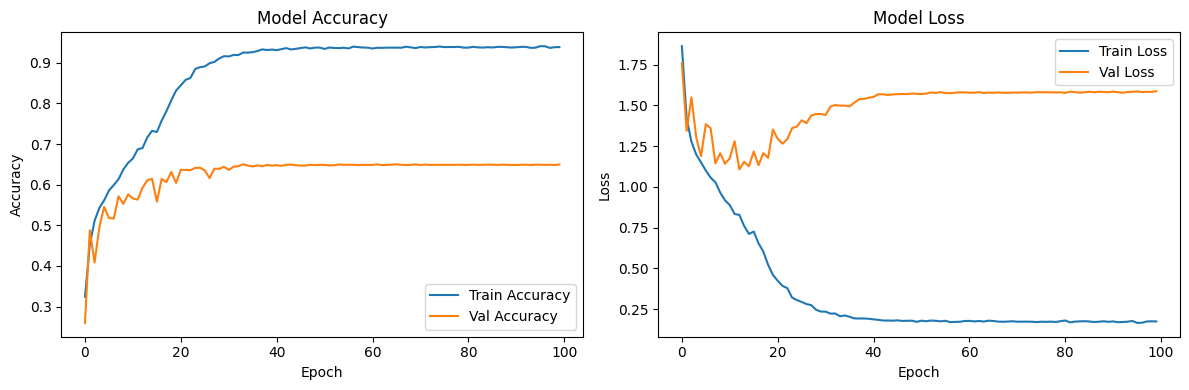

Training complete!


In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'],     label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_history.png'))
plt.show()
print('Training complete!')